# 04 Análisis exploratorio



In [ ]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = print

RAIZ = Path.cwd().parent if Path.cwd().name == "01_notebooks" else Path.cwd()
GOLD = RAIZ / "02_datos" / "gold"
SILVER = RAIZ / "02_datos" / "silver"
GRAFICOS = RAIZ / "04_graficos"
GRAFICOS.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
AZUL, NARANJA, GRIS = "#2a5d8f", "#c8742c", "#8a8a8a"

def guardar(fig, nombre, fuente):
    fig.text(0.01, 0.005, f"Fuente: {fuente}", fontsize=7.5, color=GRIS, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(GRAFICOS / nombre, dpi=160)
    plt.show()

anual = pd.read_csv(GOLD / "fact_decomiso_anual.csv")
contexto = pd.read_csv(GOLD / "fact_contexto.csv")
pais = pd.read_csv(GOLD / "dim_pais.csv")
COCA, CANN = "Cocaína y derivados", "Cannabis"
NOMBRE = dict(zip(pais["iso3"], pais["pais"]))
F71 = "UNODC, World Drug Report 2026, Annex 7.1"

## Panel fijo de países
El panel son los países con cocaína notificada en 7.1 todos los años de 2015 a 2024.

In [2]:
coca = anual[anual.grupo_droga == COCA].pivot_table(index="iso3", columns="anio", values="kg", aggfunc="sum")
panel = coca.dropna().index.tolist()
fuera = sorted(set(coca.index) - set(panel))
print(f"Panel: {len(panel)} países. Fuera por no notificar todos los años: {len(fuera)}")
print(", ".join(NOMBRE[i] for i in fuera))
assert len(panel) == 30

total_panel = coca.loc[panel].sum() / 1000
total_todos = coca.sum() / 1000
tabla = pd.DataFrame({"panel_t": total_panel, "todos_t": total_todos}).round(1)
tabla["indice_2015"] = (total_panel / total_panel[2015] * 100).round(0)
display(tabla)

Panel: 30 países. Fuera por no notificar todos los años: 14
Albania, Andorra, Bosnia y Herzegovina, Bielorrusia, Gibraltar, Islandia, Letonia, Moldavia, Macedonia del Norte, Rumanía, Eslovaquia, Eslovenia, Ucrania, Kosovo


,panel_t,todos_t,indice_2015
anio,,,
2015,85.5,85.6,100.0
2016,82.7,85.1,97.0
2017,140.8,140.8,165.0
2018,186.4,187.1,218.0
2019,207.9,212.7,243.0
2020,226.5,226.8,265.0
2021,320.5,323.0,375.0
2022,344.8,346.6,403.0
2023,447.3,447.7,523.0


## Cuánto ha crecido
Crecimiento del total de cocaína en el panel, comparado con el cannabis como grupo de control. El cannabis se mide con los países de Europa con datos todos los años, sin Türkiye. 

Panel de cannabis: 29 países
Cocaína 2024 respecto a 2015: x4.28. Máximo en 2023: x5.23
Cannabis 2024 respecto a 2015: x0.83


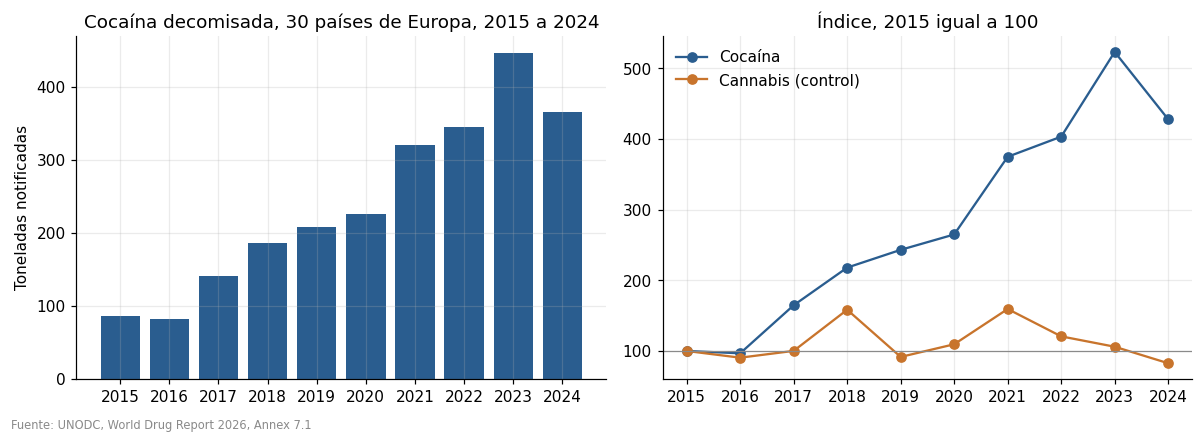

In [3]:
cann = anual[anual.grupo_droga == CANN].pivot_table(index="iso3", columns="anio", values="kg", aggfunc="sum")
panel_c = [i for i in cann.dropna().index if i != "TUR"]
total_c = cann.loc[panel_c].sum() / 1000
print(f"Panel de cannabis: {len(panel_c)} países")

veces_2024 = total_panel[2024] / total_panel[2015]
veces_2023 = total_panel[2023] / total_panel[2015]
print(f"Cocaína 2024 respecto a 2015: x{veces_2024:.2f}. Máximo en 2023: x{veces_2023:.2f}")
print(f"Cannabis 2024 respecto a 2015: x{total_c[2024] / total_c[2015]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(total_panel.index, total_panel.values, color=AZUL)
ax[0].set_title(f"Cocaína decomisada, {len(panel)} países de Europa, 2015 a 2024")
ax[0].set_ylabel("Toneladas notificadas")
ax[0].set_xticks(total_panel.index)
ax[1].plot(total_panel.index, total_panel / total_panel[2015] * 100, color=AZUL, marker="o", label="Cocaína")
ax[1].plot(total_c.index, total_c / total_c[2015] * 100, color=NARANJA, marker="o", label="Cannabis (control)")
ax[1].axhline(100, color=GRIS, lw=0.8)
ax[1].set_title("Índice, 2015 igual a 100")
ax[1].set_xticks(total_panel.index)
ax[1].legend(frameon=False)
guardar(fig, "01_crecimiento_cocaina_cannabis.png", F71)

,cocaina_t,cannabis_t,cannabis_entre_cocaina
anio,,,
2015,85.5,1056.9,12.4
2016,82.7,956.6,11.6
2017,140.8,1058.3,7.5
2018,186.4,1673.6,9.0
2019,207.9,968.1,4.7
2020,226.5,1157.1,5.1
2021,320.5,1684.7,5.3
2022,344.8,1275.4,3.7
2023,447.3,1120.5,2.5


Cannabis, máximo en 2021: 1684.7 t


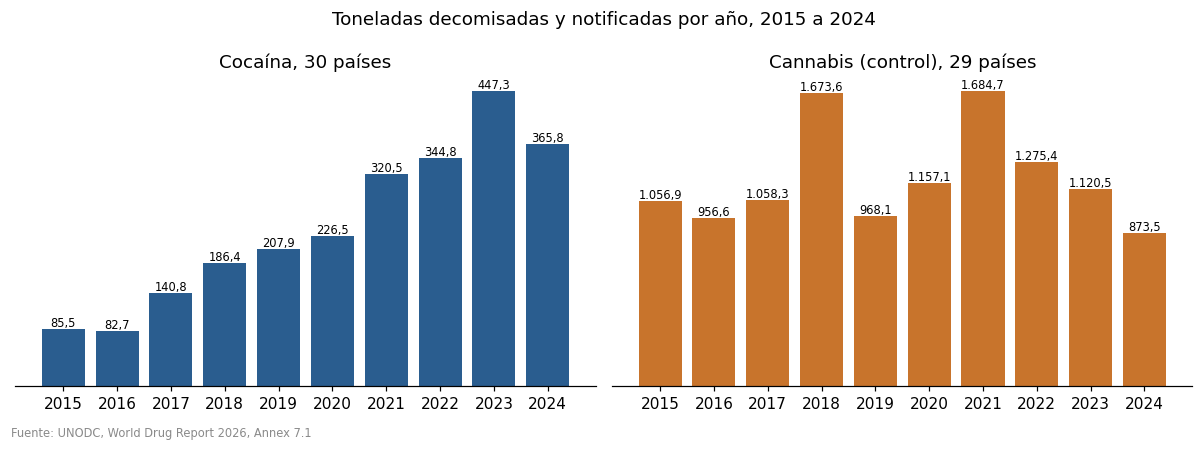

In [4]:
totales = pd.DataFrame({"cocaina_t": total_panel, "cannabis_t": total_c}).loc[2015:2024].round(1)
totales["cannabis_entre_cocaina"] = (totales.cannabis_t / totales.cocaina_t).round(1)
display(totales)
print(f"Cannabis, máximo en {total_c.idxmax()}: {total_c.max():.1f} t")

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for a, serie, color, titulo in [(ax[0], totales.cocaina_t, AZUL, f"Cocaína, {len(panel)} países"),
                                (ax[1], totales.cannabis_t, NARANJA, f"Cannabis (control), {len(panel_c)} países")]:
    a.bar(serie.index, serie.values, color=color)
    for x, v in serie.items():
        a.text(x, v, f"{v:,.1f}".replace(",", "X").replace(".", ",").replace("X", "."), ha="center", va="bottom", fontsize=7.5)
    a.set_title(titulo)
    a.set_yticks([])
    a.spines["left"].set_visible(False)
    a.grid(False)
    a.set_xticks(serie.index)
fig.suptitle("Toneladas decomisadas y notificadas por año, 2015 a 2024")
guardar(fig, "08_totales_cocaina_cannabis.png", F71)

Türkiye queda fuera del panel de cannabis por ser un valor atípico. Su cannabis pasa de unas 81 t en 2018 a unas 4.318 t en 2019, y un solo país domina el total del grupo de control. Los datos no permiten saber si el cambio es real o de notificación. La tabla muestra el índice del cannabis sin Türkiye y con Türkiye.

In [5]:
con_tur = cann.loc[panel_c + ["TUR"]].sum() / 1000
comparacion = pd.DataFrame({"sin Türkiye": total_c / total_c[2015] * 100, "con Türkiye": con_tur / con_tur[2015] * 100}).round(0)
display(comparacion.T)
display((cann.loc["TUR", 2018:2019] / 1000).round(1))

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
sin Türkiye,100.0,91.0,100.0,158.0,92.0,109.0,159.0,121.0,106.0,83.0
con Türkiye,100.0,99.0,111.0,158.0,476.0,1148.0,839.0,1108.0,1527.0,1060.0


anio
2018      80.7
2019    4318.1
Name: TUR, dtype: float64

## Dónde está el crecimiento
Aporte de cada país al aumento de 2015 a 2024. La suma de los aportes es el aumento total del panel.

Aumento total del panel: 280.3 t


España          36.6
Francia         15.2
Bélgica         10.0
Países Bajos     9.1
Reino Unido      8.1
Alemania         7.4
Portugal         6.1
Italia           2.5
Resto            5.0
Name: % del aumento, dtype: float64

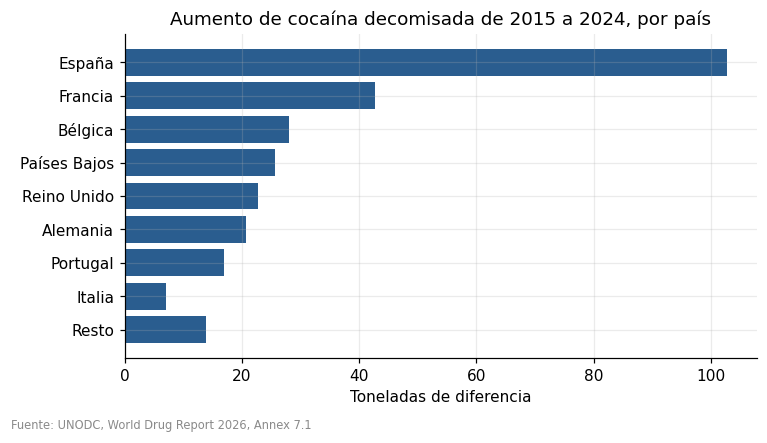

In [6]:
aporte = ((coca.loc[panel, 2024] - coca.loc[panel, 2015]) / 1000).sort_values(ascending=False)
print(f"Aumento total del panel: {aporte.sum():.1f} t")
top = aporte.head(8)
resto = aporte.iloc[8:].sum()
datos = pd.concat([top, pd.Series({"Resto": resto})])
datos.index = [NOMBRE.get(i, i) for i in datos.index]
display((datos / aporte.sum() * 100).round(1).rename("% del aumento"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(datos.index[::-1], datos.values[::-1], color=AZUL)
ax.set_title("Aumento de cocaína decomisada de 2015 a 2024, por país")
ax.set_xlabel("Toneladas de diferencia")
guardar(fig, "02_aporte_paises.png", F71)

## Dónde se concentra
Peso de cada país en la cocaína decomisada de 2024 dentro del panel.

,pais,t_2024,pct,pct_acum
0,España,124.7,34.1,34.1
1,Francia,53.5,14.6,48.7
2,Bélgica,45.5,12.4,61.1
3,Países Bajos,37.6,10.3,71.4
4,Reino Unido,28.3,7.7,79.2
5,Alemania,23.8,6.5,85.7
6,Portugal,23.0,6.3,92.0
7,Italia,11.1,3.0,95.0
8,Rusia,4.6,1.2,96.2
9,Türkiye,2.5,0.7,96.9


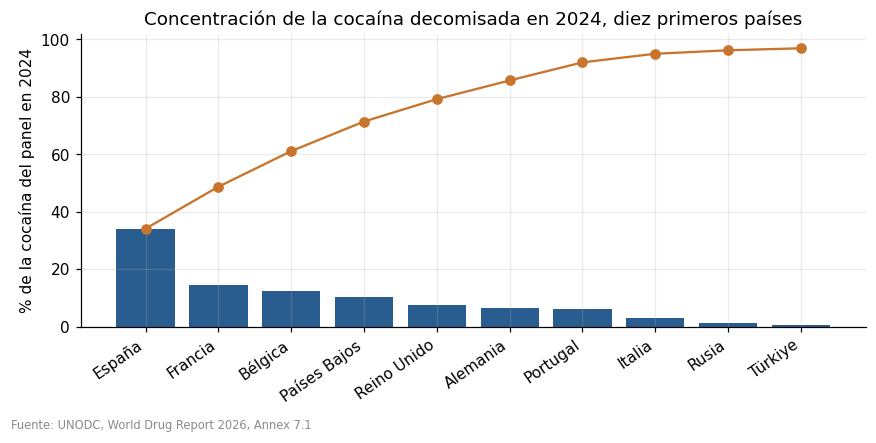

In [7]:
p24 = coca.loc[panel, 2024].sort_values(ascending=False)
cuota = (p24 / p24.sum() * 100)
acum = cuota.cumsum()
conc = pd.DataFrame({"pais": [NOMBRE[i] for i in cuota.index], "t_2024": (p24 / 1000).round(1).values,
                     "pct": cuota.round(1).values, "pct_acum": acum.round(1).values}).head(10)
display(conc)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(conc["pais"], conc["pct"], color=AZUL)
ax.plot(conc["pais"], conc["pct_acum"], color=NARANJA, marker="o")
ax.set_ylabel("% de la cocaína del panel en 2024")
ax.set_title("Concentración de la cocaína decomisada en 2024, diez primeros países")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
guardar(fig, "03_concentracion_2024.png", F71)

## Mar del Norte en 2024
Bélgica, Países Bajos y Alemania tienen los grandes puertos del Mar del Norte (Amberes, Róterdam, Hamburgo). Se compara su suma con el resto del panel.

,mar_del_norte_t,resto_t,pct_norte
anio,,,
2015,32.6,52.9,38.0
2016,44.2,38.5,53.0
2017,67.5,73.3,48.0
2018,98.2,88.2,53.0
2019,119.6,88.3,58.0
2020,130.1,96.3,57.0
2021,192.1,128.3,60.0
2022,182.4,162.4,53.0
2023,225.2,222.1,50.0


Variación 2023 a 2024. Mar del Norte: -118.3 t (-53 %). Resto del panel: 36.8 t (17 %)


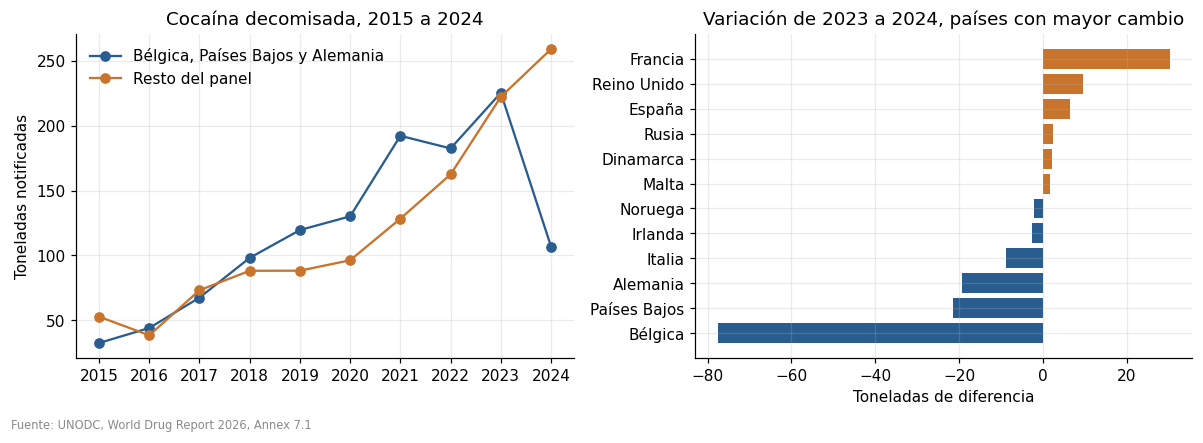

In [8]:
NORTE = ["BEL", "NLD", "DEU"]
norte = coca.loc[NORTE].sum() / 1000
resto_p = coca.loc[[i for i in panel if i not in NORTE]].sum() / 1000
comp = pd.DataFrame({"mar_del_norte_t": norte, "resto_t": resto_p}).loc[2015:2024].round(1)
comp["pct_norte"] = (comp.mar_del_norte_t / (comp.mar_del_norte_t + comp.resto_t) * 100).round(0)
display(comp)

cambio = (coca.loc[panel, 2024] - coca.loc[panel, 2023]) / 1000
print(f"Variación 2023 a 2024. Mar del Norte: {norte[2024] - norte[2023]:.1f} t ({(norte[2024] / norte[2023] - 1) * 100:.0f} %). "
      f"Resto del panel: {resto_p[2024] - resto_p[2023]:.1f} t ({(resto_p[2024] / resto_p[2023] - 1) * 100:.0f} %)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(norte.index, norte.values, color=AZUL, marker="o", label="Bélgica, Países Bajos y Alemania")
ax[0].plot(resto_p.index, resto_p.values, color=NARANJA, marker="o", label="Resto del panel")
ax[0].set_title("Cocaína decomisada, 2015 a 2024")
ax[0].set_ylabel("Toneladas notificadas")
ax[0].set_xticks(norte.index)
ax[0].legend(frameon=False)
c = cambio.sort_values()
c.index = [NOMBRE[i] for i in c.index]
sel = pd.concat([c.head(6), c.tail(6)])
ax[1].barh(sel.index, sel.values, color=[NARANJA if v > 0 else AZUL for v in sel.values])
ax[1].set_title("Variación de 2023 a 2024, países con mayor cambio")
ax[1].set_xlabel("Toneladas de diferencia")
guardar(fig, "04_mar_del_norte_2024.png", F71)

In [9]:
cuota_norte = (norte / (norte + resto_p) * 100).round(2)
print(f"Peso del Mar del Norte: {cuota_norte[2023]} % en 2023 y {cuota_norte[2024]} % en 2024")

caida_norte = norte[2023] - norte[2024]
subida_resto = resto_p[2024] - resto_p[2023]
print(f"Caída del Mar del Norte: {caida_norte:.1f} t. Subida del resto: {subida_resto:.1f} t, el {subida_resto / caida_norte * 100:.0f} % de la caída")

p23, p24 = coca.loc[panel, 2023] / 1000, coca.loc[panel, 2024] / 1000
cambio_cuota = pd.DataFrame({"t_2023": p23, "t_2024": p24, "variacion_t": p24 - p23,
                             "cuota_2023": p23 / p23.sum() * 100, "cuota_2024": p24 / p24.sum() * 100})
cambio_cuota["variacion_cuota_pp"] = cambio_cuota.cuota_2024 - cambio_cuota.cuota_2023
cambio_cuota.index = [NOMBRE[i] for i in cambio_cuota.index]
display(cambio_cuota.sort_values("variacion_cuota_pp", ascending=False).head(5).round(2))

Peso del Mar del Norte: 50.35 % en 2023 y 29.22 % en 2024
Caída del Mar del Norte: 118.3 t. Subida del resto: 36.8 t, el 31 % de la caída


,t_2023,t_2024,variacion_t,cuota_2023,cuota_2024,variacion_cuota_pp
Francia,23.20,53.50,30.30,5.19,14.63,9.44
España,118.32,124.70,6.38,26.45,34.09,7.64
Reino Unido,18.63,28.31,9.67,4.17,7.74,3.57
Portugal,21.73,23.01,1.29,4.86,6.29,1.43
Rusia,2.07,4.55,2.48,0.46,1.24,0.78


## Contraste con otras fuentes
Primero, el total de 7.1 frente a las cifras de EUDA para 2024. EUDA da 330,4 t para la UE y 333,1 t para la UE más Noruega y Türkiye.

In [10]:
UE27 = ["AUT", "BEL", "BGR", "HRV", "CYP", "CZE", "DNK", "EST", "FIN", "FRA", "DEU", "GRC", "HUN", "IRL", "ITA", "LVA", "LTU", "LUX",
        "MLT", "NLD", "POL", "PRT", "ROU", "SVK", "SVN", "ESP", "SWE"]
EUDA_2024 = {"UE": 330.4, "UE más Noruega y Türkiye": 333.1}
c24 = coca[2024] / 1000
eu = c24.reindex(UE27).sum()
eu2 = c24.reindex(UE27 + ["NOR", "TUR"]).sum()
display(pd.DataFrame({"EUDA_t": EUDA_2024, "UNODC_71_t": {"UE": round(eu, 1), "UE más Noruega y Türkiye": round(eu2, 1)}}))
assert abs(eu - 330.4) < 5

,EUDA_t,UNODC_71_t
UE,330.4,329.6
UE más Noruega y Türkiye,333.1,332.3


Segundo, el detalle de puertos de IDS frente al informe de EUDA y WCO. El informe cubre de enero de 2019 a junio de 2024 y da las toneladas de cocaína por puerto.

,EUDA_t,IDS_t,IDS_sobre_EUDA_pct
Amberes,442.9,373.4,84.0
Róterdam,180.7,0.0,0.0
Gioia Tauro,43.6,40.9,94.0
Hamburgo,41.2,10.6,26.0
Algeciras,34.8,44.3,127.0
Barcelona,32.7,32.3,99.0
Valencia,29.4,41.2,140.0


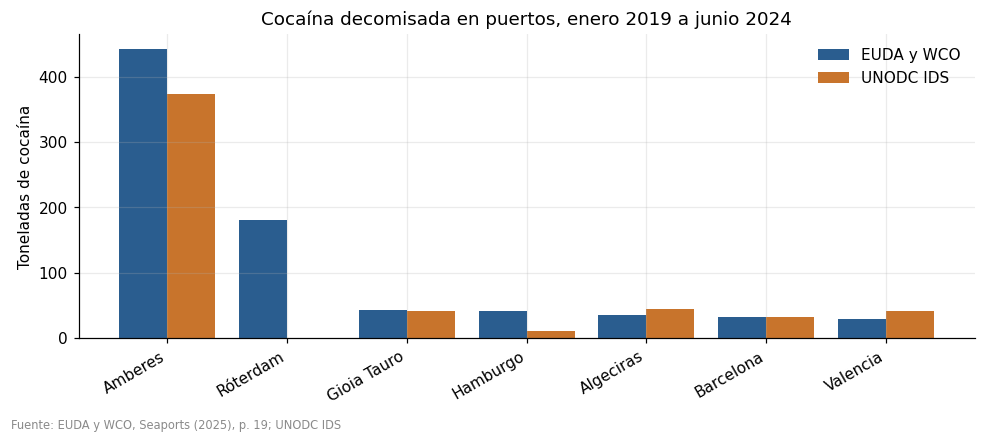

In [11]:
EUDA_PUERTOS = {"Antwerp": 442.9, "Rotterdam": 180.7, "Gioia Tauro": 43.6, "Hamburg": 41.2,
                "Algeciras": 34.8, "Barcelona": 32.7, "Valencia": 29.4}
ids = pd.read_csv(SILVER / "ids_decomisos_limpio.csv.gz",
                  usecols=["fecha", "iso3", "ciudad", "es_puerto", "grupo_droga", "cantidad_kg", "tipo_medida"], parse_dates=["fecha"])
ids = ids[(ids.tipo_medida == "masa") & (ids.grupo_droga == "Cocaina") & ids.es_puerto & ids.fecha.between("2019-01-01", "2024-06-30")]
ids["puerto"] = ids["ciudad"].replace({"Antwerpen": "Antwerp"})
ids_t = (ids.groupby("puerto")["cantidad_kg"].sum() / 1000).round(1)

cont = pd.DataFrame({"EUDA_t": pd.Series(EUDA_PUERTOS)})
ES_PUERTO = {"Antwerp": "Amberes", "Rotterdam": "Róterdam", "Hamburg": "Hamburgo"}
cont["IDS_t"] = ids_t.reindex(cont.index).fillna(0)
cont.index = [ES_PUERTO.get(p, p) for p in cont.index]
cont["IDS_sobre_EUDA_pct"] = (cont["IDS_t"] / cont["EUDA_t"] * 100).round(0)
display(cont)

x = np.arange(len(cont))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, cont["EUDA_t"], 0.4, color=AZUL, label="EUDA y WCO")
ax.bar(x + 0.2, cont["IDS_t"], 0.4, color=NARANJA, label="UNODC IDS")
ax.set_xticks(x)
ax.set_xticklabels(cont.index, rotation=30, ha="right")
ax.set_ylabel("Toneladas de cocaína")
ax.set_title("Cocaína decomisada en puertos, enero 2019 a junio 2024")
ax.legend(frameon=False)
guardar(fig, "05_ids_frente_a_euda.png", "EUDA y WCO, Seaports (2025), p. 19; UNODC IDS")

Tercero, el mismo descenso de 2023 a 2024 en Bélgica y Países Bajos según 7.1 y según EUDA.

In [12]:
EUDA_PUERTO_ANIO = pd.DataFrame({"2023": {"Amberes": 121, "Róterdam": 45}, "2024": {"Amberes": 44, "Róterdam": 26}})
s71 = pd.DataFrame({"2023": {"Amberes": coca.loc["BEL", 2023] / 1000, "Róterdam": coca.loc["NLD", 2023] / 1000},
                    "2024": {"Amberes": coca.loc["BEL", 2024] / 1000, "Róterdam": coca.loc["NLD", 2024] / 1000}}).round(1)
display(pd.concat({"EUDA, puerto": EUDA_PUERTO_ANIO, "7.1, país entero": s71}, axis=1))

EUDA, puerto      7.1, país entero      
                 2023 2024             2023  2024
Amberes           121   44            123.0  45.5
Róterdam           45   26             59.1  37.6

## Fiabilidad de IDS frente a 7.1


In [13]:
dia = pd.read_csv(GOLD / "fact_decomiso_dia.csv", parse_dates=["fecha"])
t71 = anual[(anual.grupo_droga == COCA) & anual.anio.between(2015, 2024)].groupby("anio")["kg"].sum() / 1000
tids = dia[(dia.grupo_droga == COCA) & dia.fecha.dt.year.between(2015, 2024)].groupby(dia.fecha.dt.year)["kg"].sum() / 1000
cobertura = pd.DataFrame({"7.1_t": t71.round(1), "IDS_t": tids.round(1)})
cobertura["IDS_sobre_7.1_pct"] = (cobertura["IDS_t"] / cobertura["7.1_t"] * 100).round(0)
display(cobertura)

frecuencia = pais["ids_frecuencia"].value_counts().reindex(["Alta", "Media", "Baja", "Muy baja", "Sin datos IDS"])
display(frecuencia)
print("Países con frecuencia baja, muy baja o sin datos:", int(frecuencia[["Baja", "Muy baja", "Sin datos IDS"]].sum()), "de", int(frecuencia.sum()))

salto = cobertura.loc[[2017, 2018], ["7.1_t", "IDS_t"]]
print("Variación de 2017 a 2018, en veces:")
display((salto.loc[2018] / salto.loc[2017]).round(2))

,7.1_t,IDS_t,IDS_sobre_7.1_pct
2015,85.6,26.4,31.0
2016,85.1,23.8,28.0
2017,140.8,27.3,19.0
2018,187.1,101.7,54.0
2019,212.7,110.0,52.0
2020,226.8,129.3,57.0
2021,323.0,158.1,49.0
2022,346.6,119.8,35.0
2023,447.7,270.2,60.0
2024,366.2,143.0,39.0


ids_frecuencia
Alta             13
Media            13
Baja              7
Muy baja         10
Sin datos IDS     4
Name: count, dtype: int64

Países con frecuencia baja, muy baja o sin datos: 21 de 47
Variación de 2017 a 2018, en veces:


7.1_t    1.33
IDS_t    3.73
dtype: float64

## Contexto en los tres países con más cocaína en 2024


In [14]:
top3 = (anual[(anual.grupo_droga == COCA) & (anual.anio == 2024)]
        .groupby("iso3").kg.sum().nlargest(3).index.tolist())
kg_top3 = (anual[(anual.grupo_droga == COCA) & anual.iso3.isin(top3)]
           .pivot_table(index="anio", columns="iso3", values="kg", aggfunc="sum") / 1000)
valores = contexto.pivot_table(index=["iso3", "indicador"], columns="anio", values="valor", aggfunc="mean")

filas = []
for iso in top3:
    fila = {"pais": NOMBRE[iso], "coca_2015_t": kg_top3.loc[2015, iso], "coca_2024_t": kg_top3.loc[2024, iso]}
    fila["veces_2024_sobre_2015"] = fila["coca_2024_t"] / fila["coca_2015_t"]
    for ind, y0 in [("CPI", 2015), ("GASTO_PS", 2015), ("AROPE", 2016)]:
        fila[f"{ind}_{y0}"] = valores.loc[(iso, ind), y0]
        fila[f"{ind}_2024"] = valores.loc[(iso, ind), 2024]
    filas.append(fila)
tabla_top3 = pd.DataFrame(filas).set_index("pais").round(1)
display(tabla_top3)

,coca_2015_t,coca_2024_t,veces_2024_sobre_2015,CPI_2015,CPI_2024,GASTO_PS_2015,GASTO_PS_2024,AROPE_2016,AROPE_2024
pais,,,,,,,,,
España,22.0,124.7,5.7,58.0,56.0,24.5,25.6,28.8,25.8
Francia,10.9,53.5,4.9,70.0,67.0,34.0,34.4,18.7,20.5
Bélgica,17.5,45.5,2.6,77.0,69.0,29.9,30.2,22.2,18.3


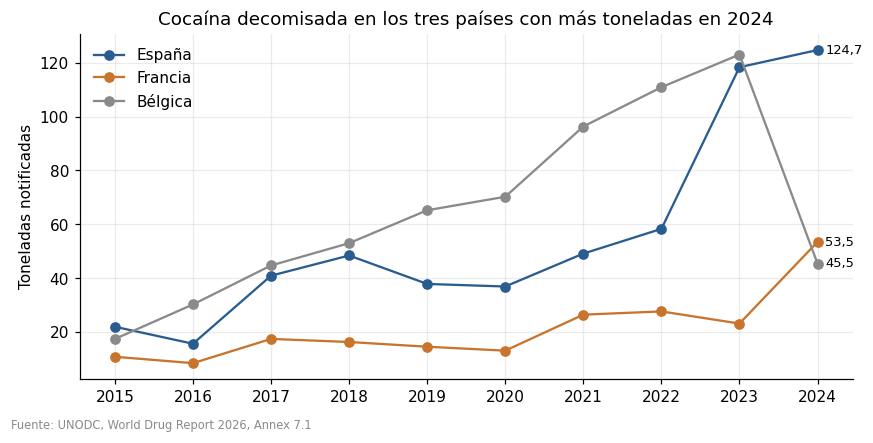

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
for iso, color in zip(top3, [AZUL, NARANJA, GRIS]):
    ax.plot(kg_top3.index, kg_top3[iso], marker="o", color=color, label=NOMBRE[iso])
    ax.text(2024.1, kg_top3.loc[2024, iso], f"{kg_top3.loc[2024, iso]:.1f}".replace(".", ","), va="center", fontsize=8.5)
ax.set_xticks(kg_top3.index)
ax.set_ylabel("Toneladas notificadas")
ax.set_title("Cocaína decomisada en los tres países con más toneladas en 2024")
ax.legend(frameon=False)
guardar(fig, "09_top3_cocaina.png", F71)

## Resumen de cifras para el informe

In [17]:
resumen = {
    "Países del panel": len(panel),
    "Cocaína 2015 (t)": round(total_panel[2015], 1),
    "Cocaína 2023 (t)": round(total_panel[2023], 1),
    "Cocaína 2024 (t)": round(total_panel[2024], 1),
    "Veces 2024 sobre 2015": round(veces_2024, 2),
    "Veces 2023 sobre 2015": round(veces_2023, 2),
    "Cannabis, veces 2024 sobre 2015": round(total_c[2024] / total_c[2015], 2),
    "Mar del Norte 2023 (t)": round(norte[2023], 1),
    "Mar del Norte 2024 (t)": round(norte[2024], 1),
    "Resto del panel 2023 (t)": round(resto_p[2023], 1),
    "Resto del panel 2024 (t)": round(resto_p[2024], 1),
    "Cuota de los 3 primeros países en 2024 (%)": round(acum.iloc[2], 1),
}
display(pd.Series(resumen, name="valor").to_frame())

,valor
Países del panel,30.00
Cocaína 2015 (t),85.50
Cocaína 2023 (t),447.30
Cocaína 2024 (t),365.80
Veces 2024 sobre 2015,4.28
Veces 2023 sobre 2015,5.23
"Cannabis, veces 2024 sobre 2015",0.83
Mar del Norte 2023 (t),225.20
Mar del Norte 2024 (t),106.90
Resto del panel 2023 (t),222.10
